# 01 · Exploración de datos: ¿por qué estas arquitecturas?

**Proyecto del curso de Deep Learning** · Juan Sebastian Higuita Riascos · Universidad Nacional de Colombia

Antes de entrenar una red hay que mirar los datos y preguntarse **qué información separa un planeta de un impostor y dónde está esa información**. Cada sección de este notebook hace una pregunta a los datos, y la respuesta motiva una rama del modelo:

| Sección | Pregunta a los datos | Decisión de arquitectura que motiva |
|---|---|---|
| 1 | ¿Qué variables sueltas separan las clases? | Rama 4: red densa pequeña sobre escalares, con aviso de dato faltante |
| 2 | ¿La forma del tránsito es distinta entre clases? | Rama 1: CNN 1D sobre la curva plegada, con 4 canales |
| 3 | ¿Cuántos tránsitos hay y qué tan limpio es cada uno? | Rama 2: leer tránsito por tránsito, máximo 32 |
| 4 | ¿Qué se pierde al promediar los tránsitos? | Rama 2: agregador (promedio, GRU o atención) |
| 5 | Resumen: de los datos a la arquitectura | — |

> Todo aquí es **descriptivo**: se mira el conjunto completo con sus etiquetas para entender el problema. Nada de este notebook elige un modelo ni un hiperparámetro; eso se hace en `02_experimentacion_hiperparametros.ipynb` con validación interna.

In [1]:
import sys
import warnings
from pathlib import Path

from IPython.display import display

warnings.filterwarnings("ignore")

# Ubicar la carpeta del repositorio y hacer visible su código (src/)
RAIZ = next(
    carpeta
    for carpeta in [Path.cwd(), *Path.cwd().parents]
    if (carpeta / "config" / "protocolo.json").is_file()
)
sys.path.insert(0, str(RAIZ / "src"))

from informe import datos, graficos
from informe.interactivo import Lista, controles

graficos.aplicar_estilo()
res = datos.cargar(RAIZ)
print(f"{len(res.ids)} ejemplos de {res.tabla.kepid.nunique()} estrellas, listos en `res`.")

from informe import exploracion, secciones

490 ejemplos de 245 estrellas, listos en `res`.


## 0 · Qué hay en el conjunto

Cada señal (KOI) da dos ejemplos: el tránsito real, etiquetado *planeta* o *falso positivo* por el catálogo DR25, y la misma estrella en una época sin tránsito (*sin señal*).

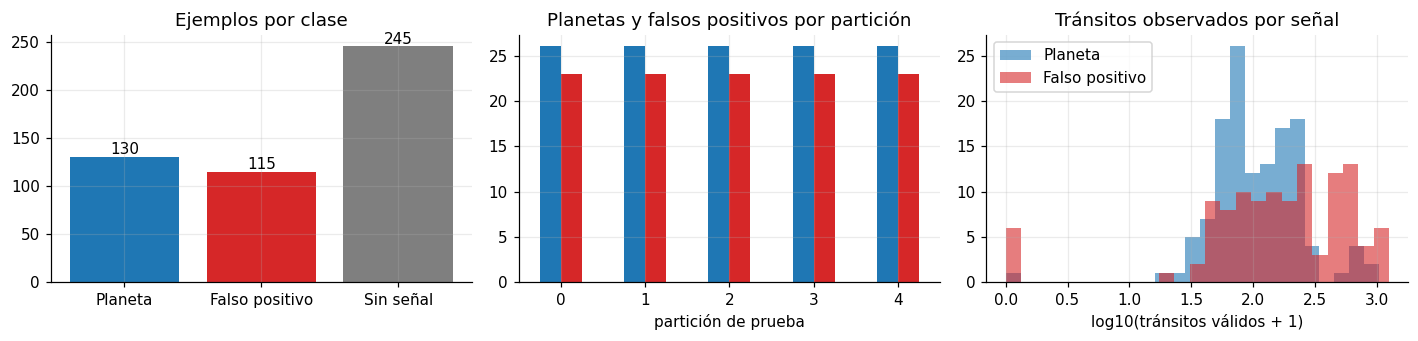

490 ejemplos de 245 estrellas · disponibles para la rama 1 (vistas): 467 · para la rama 2 (tránsitos): 471


In [2]:
secciones.resumen_de_datos(res)

## 1 · ¿Qué variables sueltas separan las clases?

Primero lo más simple: los números que resumen la señal (periodo, duración, profundidad, señal/ruido, número de tránsitos y desplazamiento de centroide).

**Qué mirar.** Si dos histogramas se superponen, esa variable por sí sola no separa. La tabla cuenta cuántas veces falta cada dato.

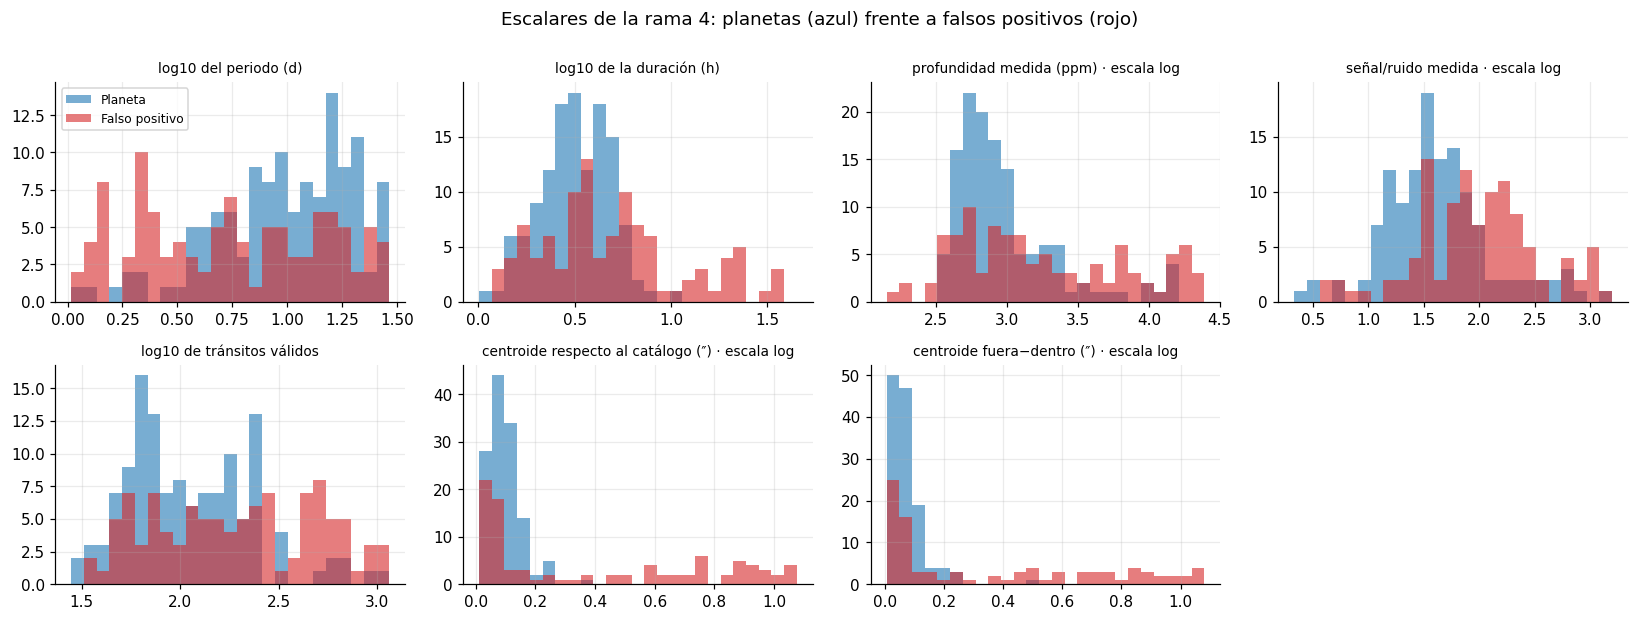

,escalar,falta en planetas,falta en falsos positivos,falta en 'sin señal'
0,log10 del periodo (d),1,6,7
1,log10 de la duración (h),1,6,7
2,profundidad medida (ppm),1,6,7
3,señal/ruido medida,1,6,7
4,log10 de tránsitos válidos,1,6,7
5,centroide respecto al catálogo (″),1,17,245
6,centroide fuera−dentro (″),1,18,245


In [3]:
tabla_faltantes = exploracion.escalares_por_clase(res)
display(tabla_faltantes)

**Lectura.**

- Ningún escalar separa las clases por sí solo: los histogramas se superponen. El **centroide** es la excepción parcial: los desplazamientos grandes solo aparecen en falsos positivos, pero muchos falsos positivos tienen un desplazamiento tan pequeño como el de un planeta.
- La información está en la **combinación**, y para combinar 7 números basta una red densa pequeña (una capa oculta). No hay estructura espacial ni temporal que justifique algo más grande.
- **Hay datos que faltan**, y no al azar: el centroide falta en varios falsos positivos y en todos los ejemplos *sin señal*. Por eso la rama 4 recibe, junto a cada valor, una **bandera de "falta"**: rellenar con 0 sin avisar le enseñaría al modelo un valor falso.
- Ese mismo patrón es una advertencia: "centroide ausente" delata la clase *sin señal*. No afecta a la métrica principal (planeta frente a falso positivo), y se declara como limitación.

### ¿Cuánto separa cada variable sola?

El AUC de una variable sola mide qué tan bien ordena planetas y falsos positivos sin ningún modelo (0,5 = nada; 1 = perfecto). En morado, estadísticos que solo existen si se miran los **tránsitos uno por uno**.

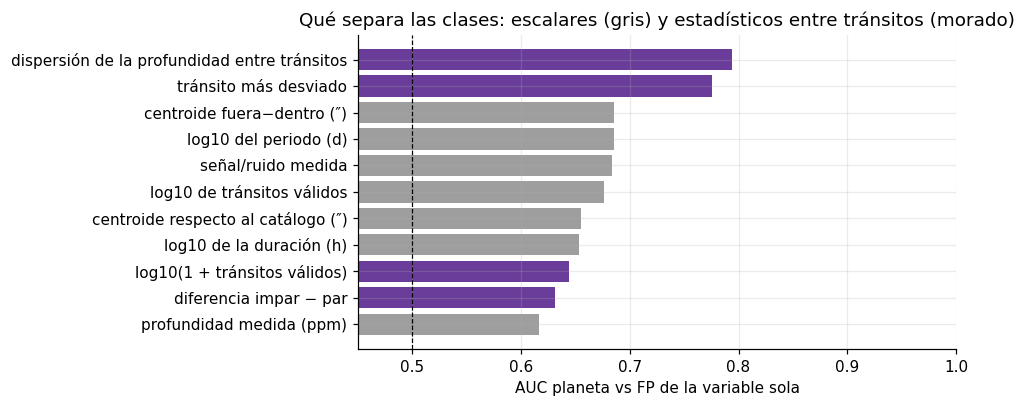

,variable,origen,auc,n
0,dispersión de la profundidad entre tránsitos,entre tránsitos (rama 2),0.794,245
1,tránsito más desviado,entre tránsitos (rama 2),0.776,245
2,centroide fuera−dentro (″),escalar (rama 4),0.685,226
3,log10 del periodo (d),escalar (rama 4),0.685,238
4,señal/ruido medida,escalar (rama 4),0.684,238
5,log10 de tránsitos válidos,escalar (rama 4),0.676,238
6,centroide respecto al catálogo (″),escalar (rama 4),0.655,227
7,log10 de la duración (h),escalar (rama 4),0.653,238
8,log10(1 + tránsitos válidos),entre tránsitos (rama 2),0.644,245
9,diferencia impar − par,entre tránsitos (rama 2),0.631,245


In [4]:
tabla_poder = exploracion.poder_de_cada_variable(res)
display(tabla_poder)

**Lectura.** Las variables que más separan por sí solas **no son los escalares clásicos, sino las que comparan un tránsito con otro** (la dispersión de la profundidad entre tránsitos y el tránsito más desviado). Esa es la primera evidencia a favor de una rama que lea los tránsitos por separado: al plegar la curva, esa información se promedia y se pierde.

Es una descripción con todos los datos, no un resultado del modelo.

## 2 · ¿La forma del tránsito es distinta entre clases?

La **vista local** es la curva plegada alrededor del tránsito. Tiene 4 canales: todos los tránsitos, solo los pares, solo los impares y la fase 0,5 (media órbita después, donde una estrella doble mostraría su eclipse secundario).

**Qué mirar.** La línea es la forma típica (mediana) de cada clase y la franja, cuánto varía (cuartiles). De la clase *sin señal* solo se dibuja la mediana, punteada. Debajo de la figura se imprimen tres medidas de forma.

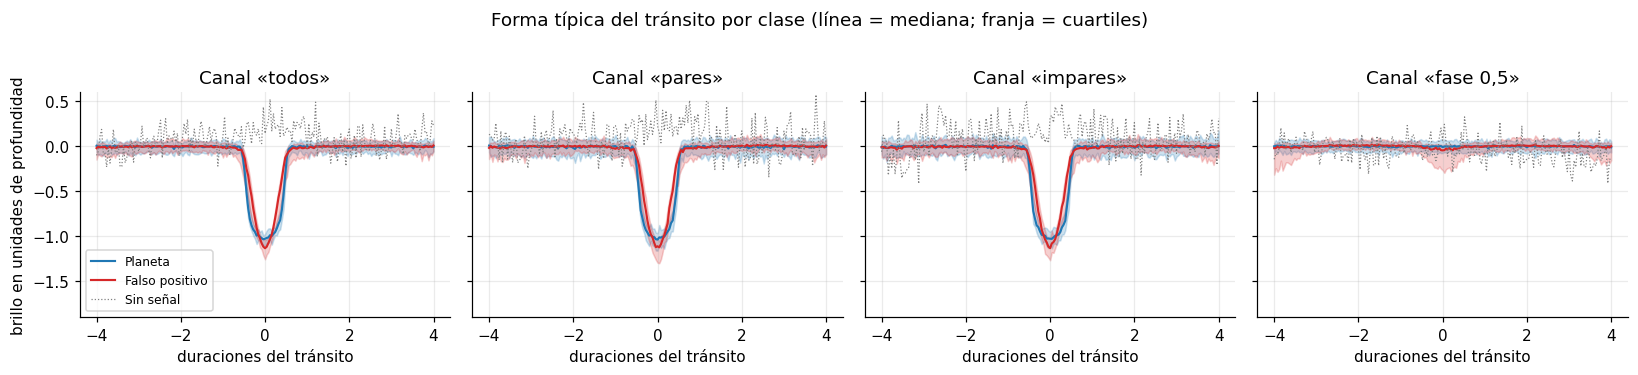

Planeta: fondo típico -1.03 · ancho a media profundidad 0.92 duraciones · el 10 % con más caída en fase 0,5 baja de -0.08
Falso positivo: fondo típico -1.13 · ancho a media profundidad 0.72 duraciones · el 10 % con más caída en fase 0,5 baja de -0.62


In [5]:
exploracion.forma_media_por_clase(res)

**Lectura.**

- Las dos formas típicas se parecen mucho: la diferencia es sutil. El falso positivo típico es **más puntiagudo** (su fondo baja más allá de −1 y es más angosto a media profundidad: forma en V), mientras el planeta tiene el fondo más plano.
- En el canal de **fase 0,5**, una parte de los falsos positivos muestra una caída (el eclipse secundario de una estrella doble) que en los planetas casi no existe.
- Son diferencias de **forma local** (pendiente de los bordes, fondo plano o en punta), y aparecen siempre en la misma posición de la ventana. Eso es justo lo que detecta una **convolución 1D**: un filtro pequeño que recorre la curva buscando un patrón. Una red densa tendría que aprender el mismo patrón en cada posición por separado.
- Los **4 canales** permiten que el mismo filtro compare pares con impares, o el tránsito con la fase 0,5, en la misma posición. Por eso se apilan como canales y no como entradas separadas.
- La mediana de la clase *sin señal* es plana, como debe ser: la época desplazada no contiene el tránsito.

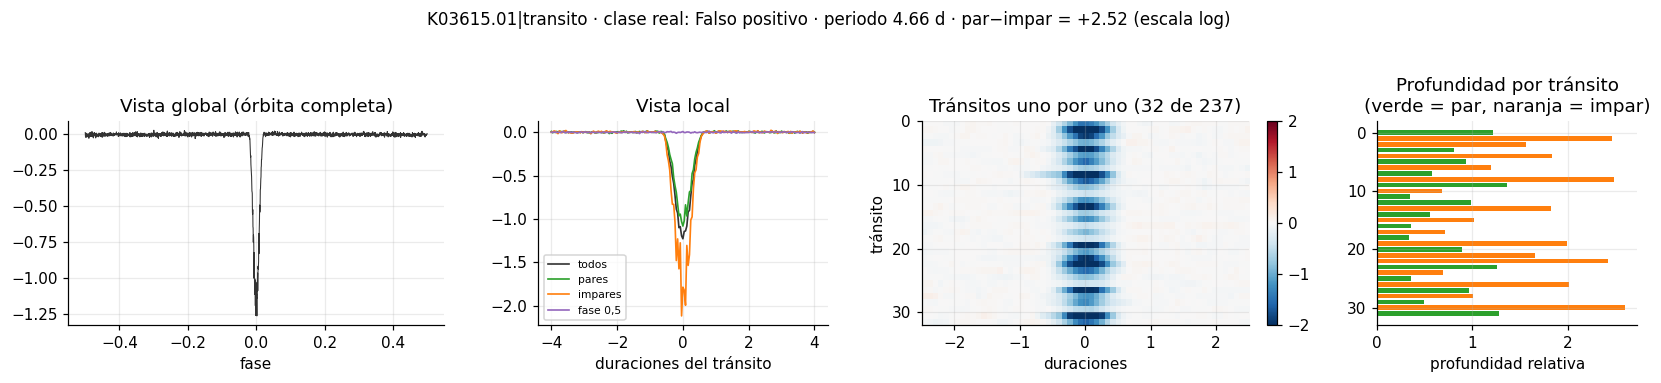

(Vista fija con Señal: K03615.01|transito. Ejecuta el notebook para usar los controles.)


In [6]:
# Mira señales concretas: compara un planeta con una estrella doble
senales = sorted(res.ids[res.y < 2])
ilustrativos = ["K03615.01|transito", "K00022.01|transito"]
opciones = ilustrativos + [s for s in senales if s not in ilustrativos]

controles(
    lambda id_ejemplo: graficos.ver_ejemplo(res, id_ejemplo),
    id_ejemplo=Lista("Señal:", opciones),
)

## 3 · ¿Cuántos tránsitos hay y qué tan limpio es cada uno?

Para leer tránsito por tránsito hacen falta dos cosas: que haya varios, y que cada uno se distinga del ruido.

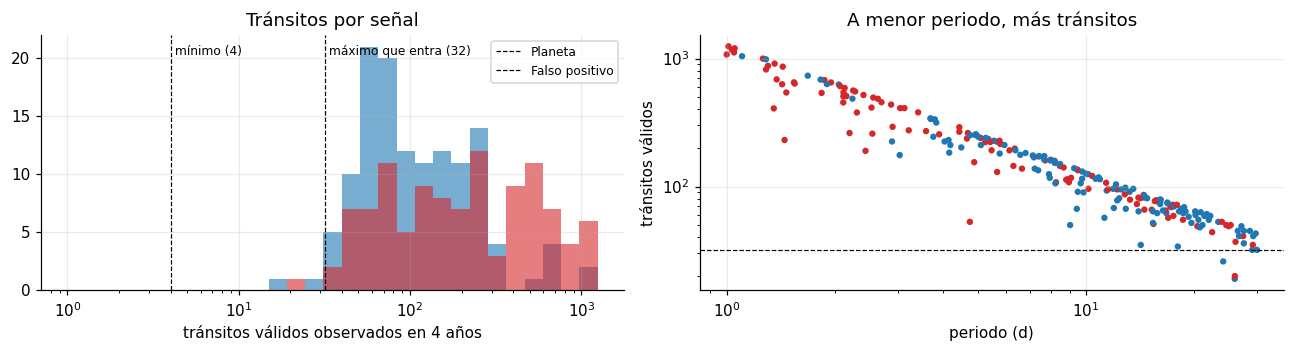

Mediana: 125 tránsitos por señal. El 95% de las señales tiene más de 32: de esas se toma una muestra repartida en el tiempo.


In [7]:
exploracion.transitos_por_senal(res)

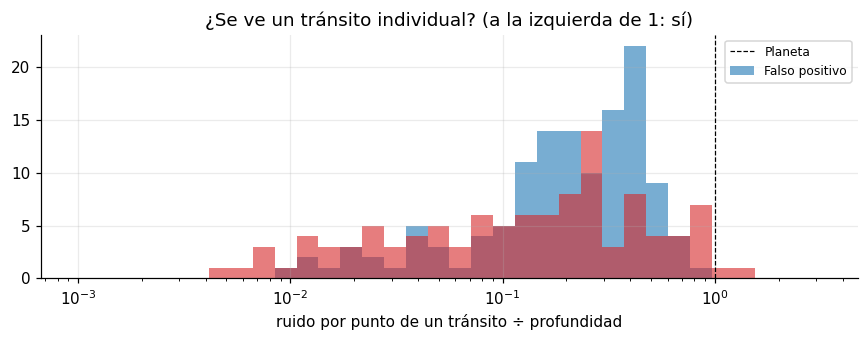

Planeta: mediana 0.21; en el 8% el ruido por punto supera la mitad de la profundidad.
Falso positivo: mediana 0.15; en el 16% el ruido por punto supera la mitad de la profundidad.


In [8]:
exploracion.ruido_de_un_transito(res)

**Lectura.**

- En periodo corto hay **muchos tránsitos por señal**, casi siempre más de 32. La rama 2 toma hasta 32, repartidos en el tiempo y mitad pares, mitad impares: suficiente para comparar tránsitos entre sí sin que el modelo crezca con el número de tránsitos.
- En la mayoría de las señales **un tránsito individual se ve**: el ruido de cada punto es bastante menor que la profundidad. Tiene sentido entonces darle a la red cada tránsito por separado.
- Esto también anticipa un límite: con tantos tránsitos limpios, **promediar ya funciona bien**. La ventaja de un agregador más flexible (atención) debería notarse con *pocos* tránsitos o más ruido, que es el caso de la zona habitable y no el de estos datos.

## 4 · ¿Qué se pierde al promediar los tránsitos?

Tres medidas que solo existen tránsito por tránsito: la diferencia entre impares y pares (firma de una estrella doble con dos eclipses distintos), la dispersión de la profundidad y el tránsito que más se aparta de los demás.

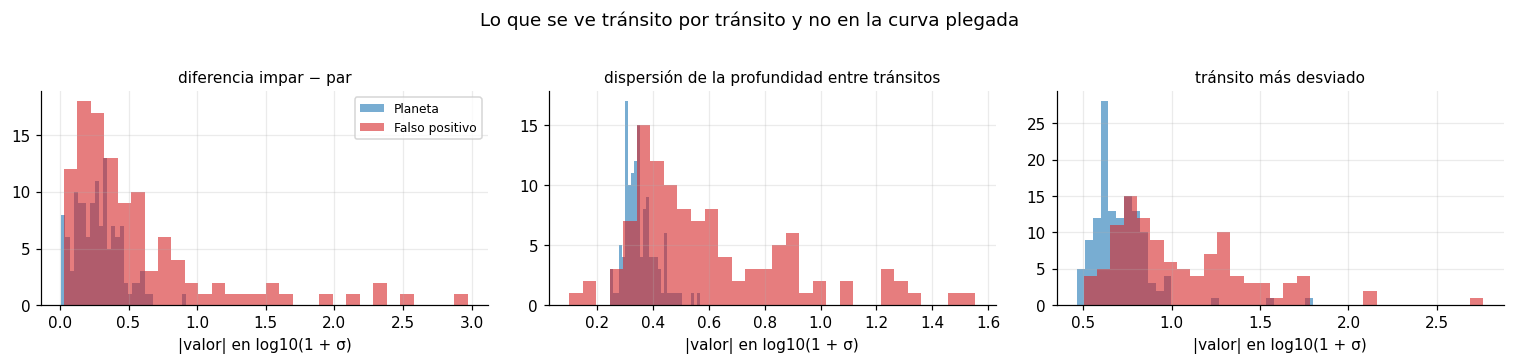

In [9]:
exploracion.consistencia_entre_transitos(res)

**Lectura.** En los falsos positivos estas medidas tienen **colas largas** que los planetas casi no tienen: tránsitos que no se repiten igual. La curva plegada las borra por construcción.

De aquí salen las tres variantes de la rama 2, que comparten el mismo codificador por tránsito (una CNN 1D pequeña con los **mismos pesos** para todos los tránsitos, porque un tránsito es un tránsito sin importar cuál sea):

| Agregador | Qué supone sobre los datos | Qué puede aprovechar |
|---|---|---|
| Promedio | Todos los tránsitos valen lo mismo y el orden no importa | Nada más que la curva plegada; es la referencia |
| GRU | El orden cronológico importa | Cambios a lo largo del tiempo |
| Atención | Algunos tránsitos importan más; el orden no importa | El tránsito que se aparta de los demás |

Cuál gana es una pregunta empírica: la responden `informe_dl.ipynb` (protocolo fijo) y `02_experimentacion_hiperparametros.ipynb` (con búsqueda).

## 5 · De los datos a la arquitectura

| Lo que muestran los datos | Decisión | Dónde está en el código |
|---|---|---|
| 7 números que solo separan combinados; algunos faltan | Red densa de una capa oculta + banderas de faltante | `temporal/modelos.py · m4_escalares` |
| Diferencias de forma local, en posición fija, entre 4 vistas | CNN 1D con las vistas como canales | `m1_astronet` |
| Muchos tránsitos, cada uno visible | Codificador compartido por tránsito, hasta 32 | `codificador_por_transito`, `m2` |
| La información entre tránsitos se pierde al plegar | Agregador: promedio, GRU o atención | `m2(agregador=…)` |
| Ramas con información distinta y a veces ausente | Fusión de vectores con banderas de disponibilidad | `fusion/fusionar.py` |
| Pocas señales (245) | Modelos pequeños, dropout, aumentación, parada temprana y validación cruzada por estrella | `comun/entrenamiento.py` |

**Lo que este notebook no puede decir:** qué tamaño de red, qué tasa de aprendizaje o cuánto dropout conviene. Eso no se deduce mirando datos: se mide. Sigue en el notebook 02.